In [1]:
from pathlib import Path
import sys

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"

In [2]:
import numpy as np

train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_test, y_test = test_data["X"], test_data["y"]

Device: cpu


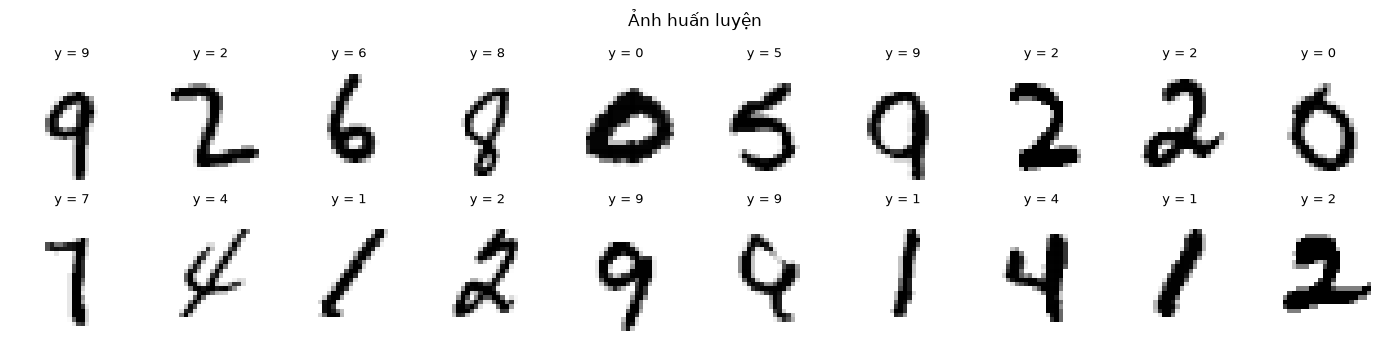

CNN(
  (layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=3136, out_features=128, bias=True)
    (8): ReLU()
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)
Epoch 1/5 | Train loss: 0.0695, acc: 0.9796 | Val loss: 0.0795, acc: 0.9752
Epoch 2/5 | Train loss: 0.0479, acc: 0.9857 | Val loss: 0.0576, acc: 0.9825
Epoch 3/5 | Train loss: 0.0398, acc: 0.9879 | Val loss: 0.0581, acc: 0.9831
Epoch 4/5 | Train loss: 0.0311, acc: 0.9898 | Val loss: 0.0498, acc: 0.9838
Epoch 5/5 | Train loss: 0.0163, acc: 0.9952 | Val loss: 0.0396, acc: 0.9886
Đã lưu trọng số vào: mnist_cnn.pth


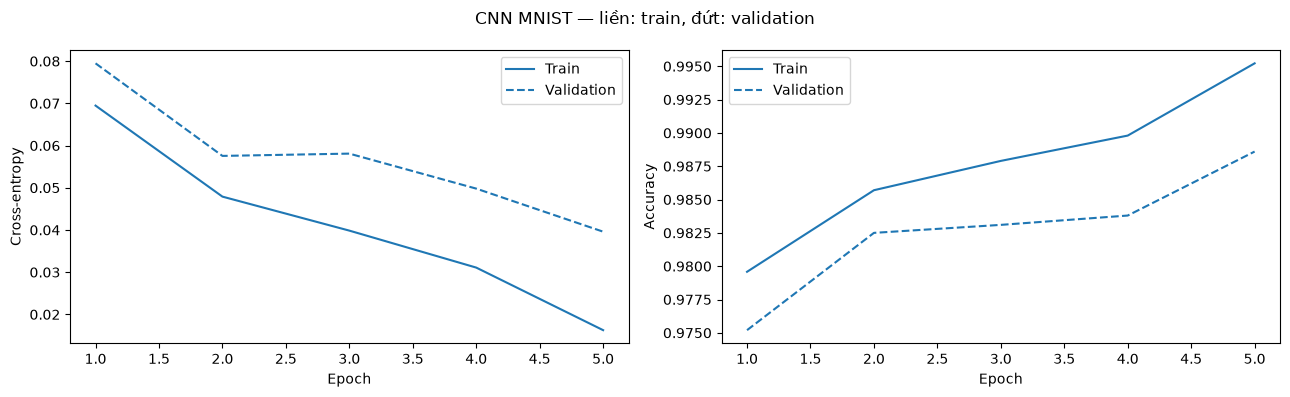

Test loss: 0.0294 | Test accuracy: 0.9898


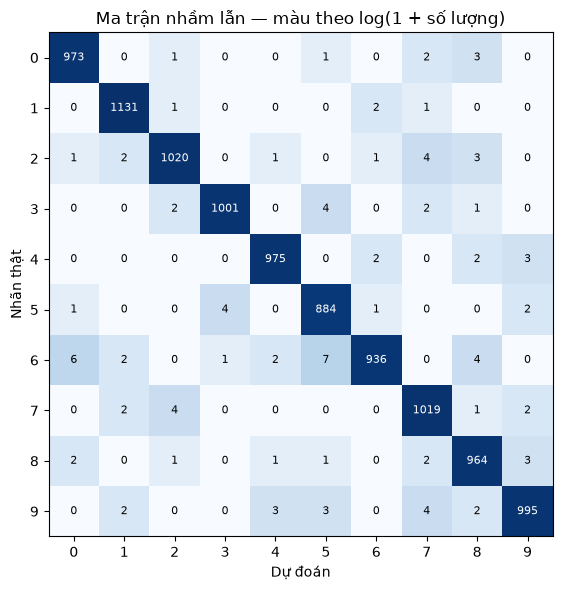

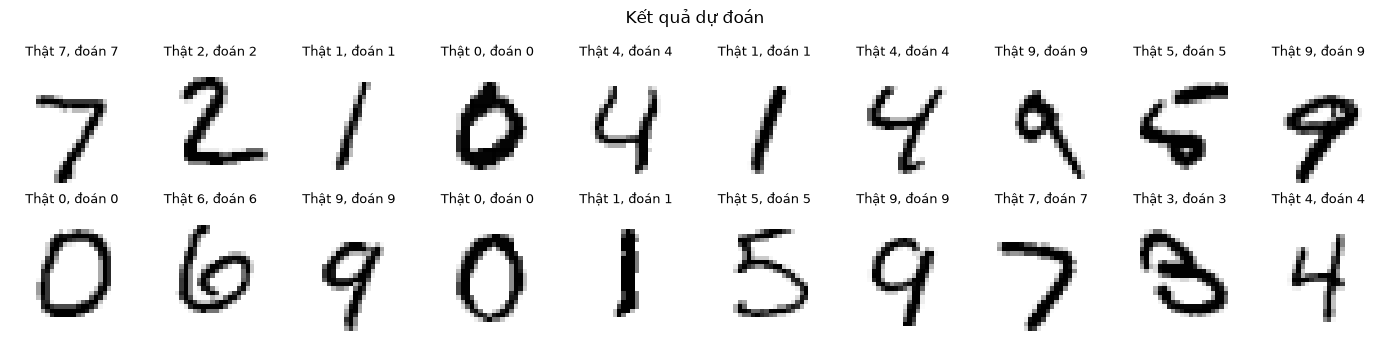

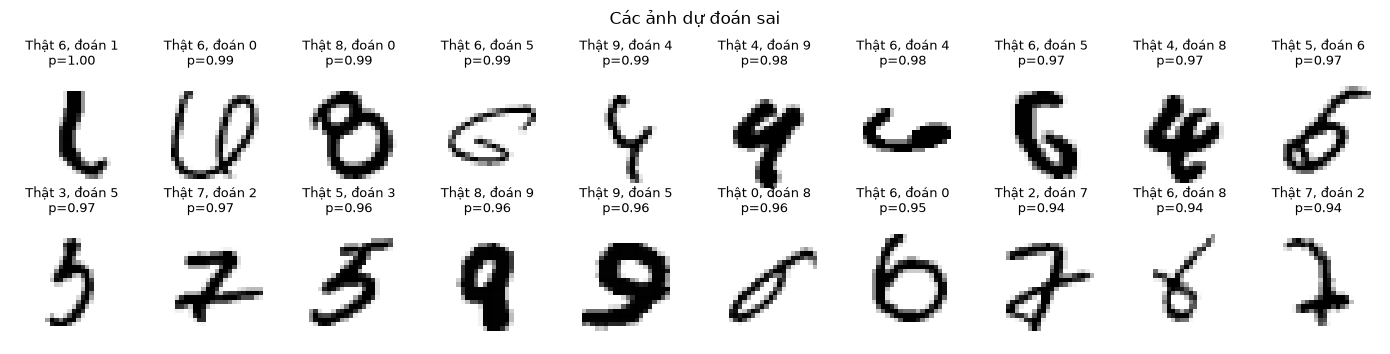

In [3]:
from src.models.cnn import CNN, read_dataset, main as main_for_cnn, predict
from torch.utils.data import DataLoader, Subset
import time
import torch
time_train_cnn = main_for_cnn()

**Load and use CNN model**

In [4]:
@torch.no_grad()
def predict_with_loader(model, data_loader):
    """
    Nhận vào mô hình và một đối tượng DataLoader.
    Trả về: 3 danh sách gồm toàn bộ (Nhãn thật, Chữ số dự đoán, Độ tự tin)
    """
    model.eval()
    device = next(model.parameters()).device
    
    all_labels = []
    all_preds = []
    all_confidences = []
    
    # Duyệt qua từng batch dữ liệu từ DataLoader
    for images, labels in data_loader:
        images = images.to(device)
        
        # Dự đoán
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        confidences, predicteds = probabilities.max(dim=1)
        
        # Lưu kết quả của batch này lại
        all_labels.extend(labels.tolist())
        all_preds.extend(predicteds.tolist())
        all_confidences.extend(confidences.tolist())
        
    return all_labels, all_preds, all_confidences

In [5]:
data = read_dataset()
test_data = data['test_data']

# install model trained
model = CNN()
checkpoint = torch.load('mnist_cnn.pth', map_location=torch.device('cpu'))
model.load_state_dict(checkpoint)

<All keys matched successfully>

In [6]:
test_subset = Subset(test_data, range(10))
sample_loader = DataLoader(test_subset, batch_size=10, shuffle=False)

labels, digits, confidences = predict_with_loader(model, sample_loader)

for i, (l, d, c) in enumerate(zip(labels, digits, confidences)):
    print(f"Ảnh {i+1:<6} | Nhãn thật: {l:<6} | Dự đoán: {d:<6} | Độ tự tin: {c:.2%}")

Ảnh 1      | Nhãn thật: 7      | Dự đoán: 7      | Độ tự tin: 100.00%
Ảnh 2      | Nhãn thật: 2      | Dự đoán: 2      | Độ tự tin: 100.00%
Ảnh 3      | Nhãn thật: 1      | Dự đoán: 1      | Độ tự tin: 99.99%
Ảnh 4      | Nhãn thật: 0      | Dự đoán: 0      | Độ tự tin: 100.00%
Ảnh 5      | Nhãn thật: 4      | Dự đoán: 4      | Độ tự tin: 100.00%
Ảnh 6      | Nhãn thật: 1      | Dự đoán: 1      | Độ tự tin: 99.99%
Ảnh 7      | Nhãn thật: 4      | Dự đoán: 4      | Độ tự tin: 99.99%
Ảnh 8      | Nhãn thật: 9      | Dự đoán: 9      | Độ tự tin: 99.49%
Ảnh 9      | Nhãn thật: 5      | Dự đoán: 5      | Độ tự tin: 98.86%
Ảnh 10     | Nhãn thật: 9      | Dự đoán: 9      | Độ tự tin: 99.98%


In [8]:
# predict
loader = DataLoader(test_data, batch_size=10, shuffle=False)

# calculate time for test
start_time = time.perf_counter()
labels, digits, confidences = predict_with_loader(model, loader)
end_time = time.perf_counter()
time_test_cnn = end_time - start_time

In [9]:
time_test_cnn

2.185750910000934

In [11]:
time = {'train' : time_train_cnn, 'test' : time_test_cnn}
time

{'train': 139.24341709299915, 'test': 2.185750910000934}

In [24]:
# danh gia voi metric cua sklearn
from sklearn.metrics import classification_report
print(classification_report(labels, digits))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.99       892
           6       0.99      0.98      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.98      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [25]:
# danh gia voi metric tu implement
from src.evaluation.metrics import ClassificationMetrics
metrics_ = ClassificationMetrics(labels, digits)
metrics_.report()

     Class  Precision     Recall         F1
         0      0.990      0.993      0.991 
         1      0.993      0.996      0.995 
         2      0.991      0.988      0.990 
         3      0.995      0.991      0.993 
         4      0.993      0.993      0.993 
         5      0.982      0.991      0.987 
         6      0.994      0.977      0.985 
         7      0.985      0.991      0.988 
         8      0.984      0.990      0.987 
         9      0.990      0.986      0.988 
 Macro avg      0.990      0.990      0.990 

Accuracy: 0.990
